# Distribución de ventas y valores atípicos

Analizamos `Sales` por `Category` en el conjunto limpio Sample Superstore, reutilizado de la entrega del módulo 11. Cada fila representa una línea de pedido. La copia local permite ejecutar el análisis sin modificar la fuente.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

data_path = Path('data/dashboard_ventas.csv')
sales_data = pd.read_csv(data_path)
print(f'Filas: {len(sales_data):,} | Columnas: {len(sales_data.columns)}')
print(f'Valores faltantes: {sales_data.isna().sum().sum()}')
display(sales_data.head())

Filas: 9,994 | Columnas: 21
Valores faltantes: 0


,Order ID,Order Date,Ship Date,Ship Mode,Segment,Region,State,City,Category,Sub-Category,...,Sales,Quantity,Discount,Profit,Year,Quarter,QuarterLabel,Month,MonthName,YearMonth
0,CA-2017-152156,2017-11-08,2017-11-11,Second Class,Consumer,South,Kentucky,Henderson,Furniture,Bookcases,...,261.9600,2.0,0.00,41.9136,2017,4,Q4 2017,11,Nov,2017-11
1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,Consumer,South,Kentucky,Henderson,Furniture,Chairs,...,731.9400,3.0,0.00,219.5820,2017,4,Q4 2017,11,Nov,2017-11
2,CA-2017-138688,2017-06-12,2017-06-16,Second Class,Corporate,West,California,Los Angeles,Office Supplies,Labels,...,14.6200,2.0,0.00,6.8714,2017,2,Q2 2017,6,Jun,2017-06
3,US-2016-108966,2016-10-11,2016-10-18,Standard Class,Consumer,South,Florida,Fort Lauderdale,Furniture,Tables,...,957.5775,5.0,0.45,-383.0310,2016,4,Q4 2016,10,Oct,2016-10
4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,Consumer,South,Florida,Fort Lauderdale,Office Supplies,Storage,...,22.3680,2.0,0.20,2.5164,2016,4,Q4 2016,10,Oct,2016-10


## Resumen de `Sales`

La asimetría positiva indica una cola hacia ventas altas. La curtosis de pandas es de exceso: usa cero como referencia para una distribución normal.

In [2]:
sales = sales_data['Sales']
sales_summary = pd.Series({
    'Media': sales.mean(),
    'Mediana': sales.median(),
    'Asimetría': sales.skew(),
    'Curtosis de exceso': sales.kurt(),
})
display(sales_summary.round(4).to_frame('Sales'))
display(sales_data.groupby('Category')['Sales'].agg(['count', 'mean', 'median']).round(2))

,Sales
Media,229.8580
Mediana,54.4900
Asimetría,12.9728
Curtosis de exceso,305.3118


,count,mean,median
Category,,,
Furniture,2121,349.83,182.22
Office Supplies,6026,119.32,27.42
Technology,1847,452.71,166.16


## Comparación visual por categoría

El gráfico de barras compara la cantidad de líneas registradas por categoría, no los importes vendidos. El boxplot muestra mediana, cuartiles y posibles valores extremos; el violin plot muestra la forma estimada de la distribución. Estas dos visualizaciones usan los valores originales y la misma escala de ventas.

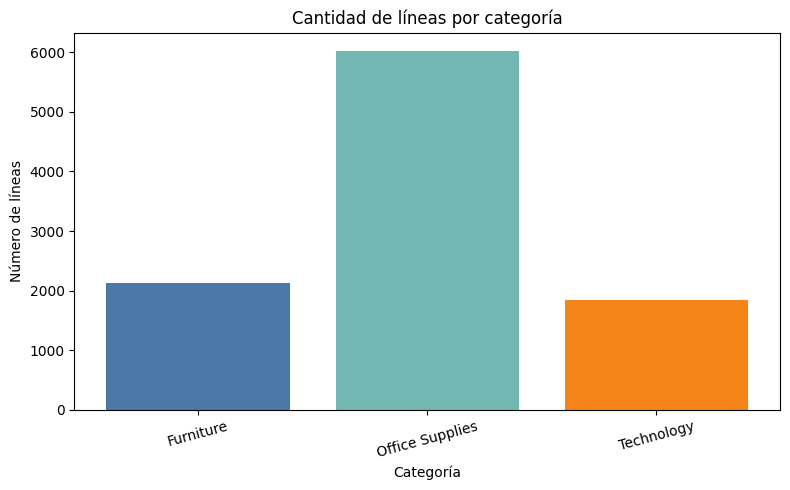

In [3]:
category_sales = sales_data.groupby('Category')['Sales']
category_counts = sales_data['Category'].value_counts().sort_index()
categories = category_counts.index.tolist()
sales_by_category = [sales_data.loc[sales_data['Category'].eq(category), 'Sales'].to_numpy()
                     for category in categories]

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(categories, category_counts.values, color=['#4c78a8', '#72b7b2', '#f58518'])
ax.set(title='Cantidad de líneas por categoría', xlabel='Categoría', ylabel='Número de líneas')
ax.tick_params(axis='x', rotation=15)
fig.tight_layout()
plt.show()

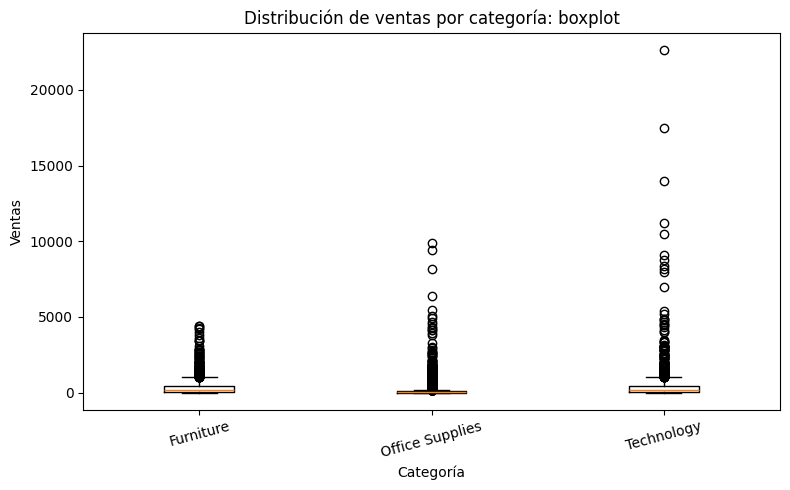

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(sales_by_category, tick_labels=categories, showfliers=True)
ax.set(title='Distribución de ventas por categoría: boxplot', xlabel='Categoría', ylabel='Ventas')
ax.tick_params(axis='x', rotation=15)
fig.tight_layout()
plt.show()

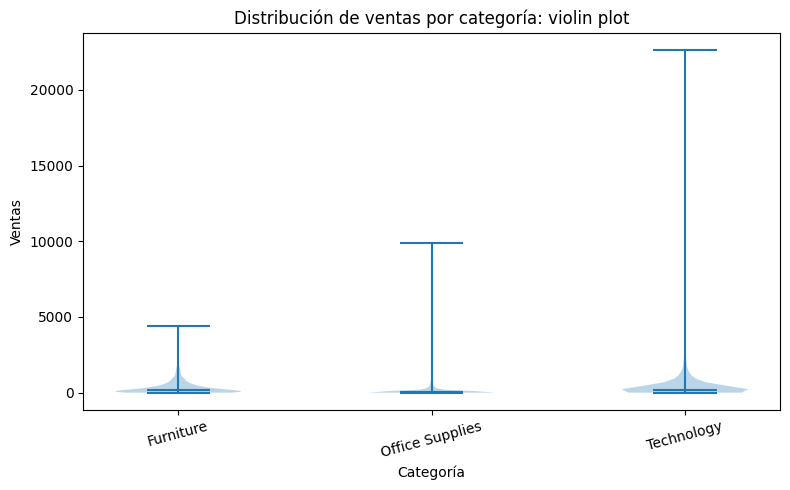

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.violinplot(sales_by_category, showmedians=True, showextrema=True)
ax.set_xticks(range(1, len(categories) + 1), categories, rotation=15)
ax.set(title='Distribución de ventas por categoría: violin plot', xlabel='Categoría', ylabel='Ventas')
fig.tight_layout()
plt.show()

Las colas altas comprimen la zona donde se concentra gran parte de las observaciones en la escala original. El ancho del violín representa densidad estimada, no cantidad de filas. Los puntos del boxplot son indicadores estadísticos, no pruebas de errores.

## Segmentación mediante IQR

Para cada categoría calculamos Q1 y Q3 de `Sales`, luego IQR = Q3 − Q1. Marcamos una línea si su venta es estrictamente menor que Q1 − 1,5 × IQR o mayor que Q3 + 1,5 × IQR. Los valores exactamente en los límites no se marcan. No eliminamos registros.

In [6]:
# Calculate fences separately for each category, then align them with every source row.
quartiles = category_sales.quantile([0.25, 0.75]).unstack()
quartiles.columns = ['sales_q1', 'sales_q3']
quartiles['sales_iqr'] = quartiles['sales_q3'] - quartiles['sales_q1']
quartiles['sales_lower_fence'] = quartiles['sales_q1'] - 1.5 * quartiles['sales_iqr']
quartiles['sales_upper_fence'] = quartiles['sales_q3'] + 1.5 * quartiles['sales_iqr']

flagged_data = sales_data.join(quartiles, on='Category')
flagged_data['sales_iqr_outlier'] = (
    (flagged_data['Sales'] < flagged_data['sales_lower_fence'])
    | (flagged_data['Sales'] > flagged_data['sales_upper_fence'])
)
outliers = flagged_data.loc[flagged_data['sales_iqr_outlier']].copy()
category_summary = flagged_data.groupby('Category')['sales_iqr_outlier'].agg(
    total='size', marcados='sum'
)
category_summary['porcentaje'] = 100 * category_summary['marcados'] / category_summary['total']
display(quartiles.round(2))
display(category_summary.round(2))
print(f'Total de líneas marcadas: {len(outliers):,} de {len(flagged_data):,}')
display(outliers[['Category', 'Sales', 'sales_lower_fence', 'sales_upper_fence']].head(10))

,sales_q1,sales_q3,sales_iqr,sales_lower_fence,sales_upper_fence
Category,,,,,
Furniture,47.04,435.17,388.13,-535.15,1017.36
Office Supplies,11.76,79.92,68.16,-90.48,182.16
Technology,68.02,448.53,380.52,-502.76,1019.31


,total,marcados,porcentaje
Category,,,
Furniture,2121,164,7.73
Office Supplies,6026,815,13.52
Technology,1847,172,9.31


Total de líneas marcadas: 1,151 de 9,994


,Category,Sales,sales_lower_fence,sales_upper_fence
10,Furniture,1706.184,-535.152,1017.360
13,Office Supplies,407.976,-90.480,182.160
16,Office Supplies,665.880,-90.480,182.160
24,Furniture,1044.630,-535.152,1017.360
27,Furniture,3083.430,-535.152,1017.360
35,Technology,1097.544,-502.761,1019.311
46,Office Supplies,211.960,-90.480,182.160
54,Technology,1029.950,-502.761,1019.311
55,Office Supplies,208.560,-90.480,182.160
67,Office Supplies,1113.024,-90.480,182.160


In [7]:
# Export all original fields plus the category-specific fences and flag.
output_path = Path('outputs/outliers_sales_iqr.csv')
output_path.parent.mkdir(parents=True, exist_ok=True)
outliers.to_csv(output_path, index=False)
print(f'Registros exportados: {len(outliers):,} -> {output_path}')

Registros exportados: 1,151 -> outputs\outliers_sales_iqr.csv


## Interpretación y decisión

En la instantánea de referencia se marcan 1.151 de 9.994 líneas: 164 de Furniture, 815 de Office Supplies y 172 de Technology. La media de ventas (229,858) supera ampliamente la mediana (54,49); junto con la asimetría positiva y los gráficos, esto es coherente con una cola derecha larga.

Conservamos las filas porque pueden representar operaciones válidas. Antes de corregir o eliminar alguna, revisaríamos su origen y contexto. Para modelos sensibles a extremos, podríamos comparar una transformación `log1p` —si las ventas son no negativas— con el análisis en escala original. El CSV exportado facilita la revisión sin alterar los datos de entrada.